##Mann-Whitney U Test Results Aanalysis

In [1]:
import pandas as pd
path = r"C:\Users\papan\Desktop\Coffeeomics\metabolomics\mann_whitney_results\mann_whitney_results_analysis\green_highlight_records.csv"
mw_results = pd.read_csv(path, index_col=0)
mw_results.head(3)

,species,metabolite,contrast
file,,,
mannwhiteneyu_co2.xlsx,C. arabica,Isoleucine,380 vs 700 | 42/30°C | without
mannwhiteneyu_co2.xlsx,C. arabica,Threonine,380 vs 700 | 42/30°C | without
mannwhiteneyu_co2.xlsx,C. arabica,Fumarate,380 vs 700 | 42/30°C | without


In [30]:
TOP_N = 20

top_contrasts_per_species = (
    mw_results
    .groupby(["species", "file", "contrast"])
    .size()
    .reset_index(name="n_highlights")
    .sort_values(["species", "n_highlights"], ascending=[True, False])
    .groupby("species")
    .head(TOP_N)
    .reset_index(drop=True)
)

top_contrasts_per_species.head(3)

,species,file,contrast,n_highlights
0,C. arabica,mannwhiteneyu_temperature.xlsx,42/30°C vs Rec 14 - 25/20°C | 380ppm | severe,26
1,C. arabica,mannwhiteneyu_temperature.xlsx,42/30°C vs Rec 14 - 25/20°C | 700ppm | severe,22
2,C. arabica,mannwhiteneyu_temperature.xlsx,42/30°C vs Rec 14 - 25/20°C | 380ppm | without,20


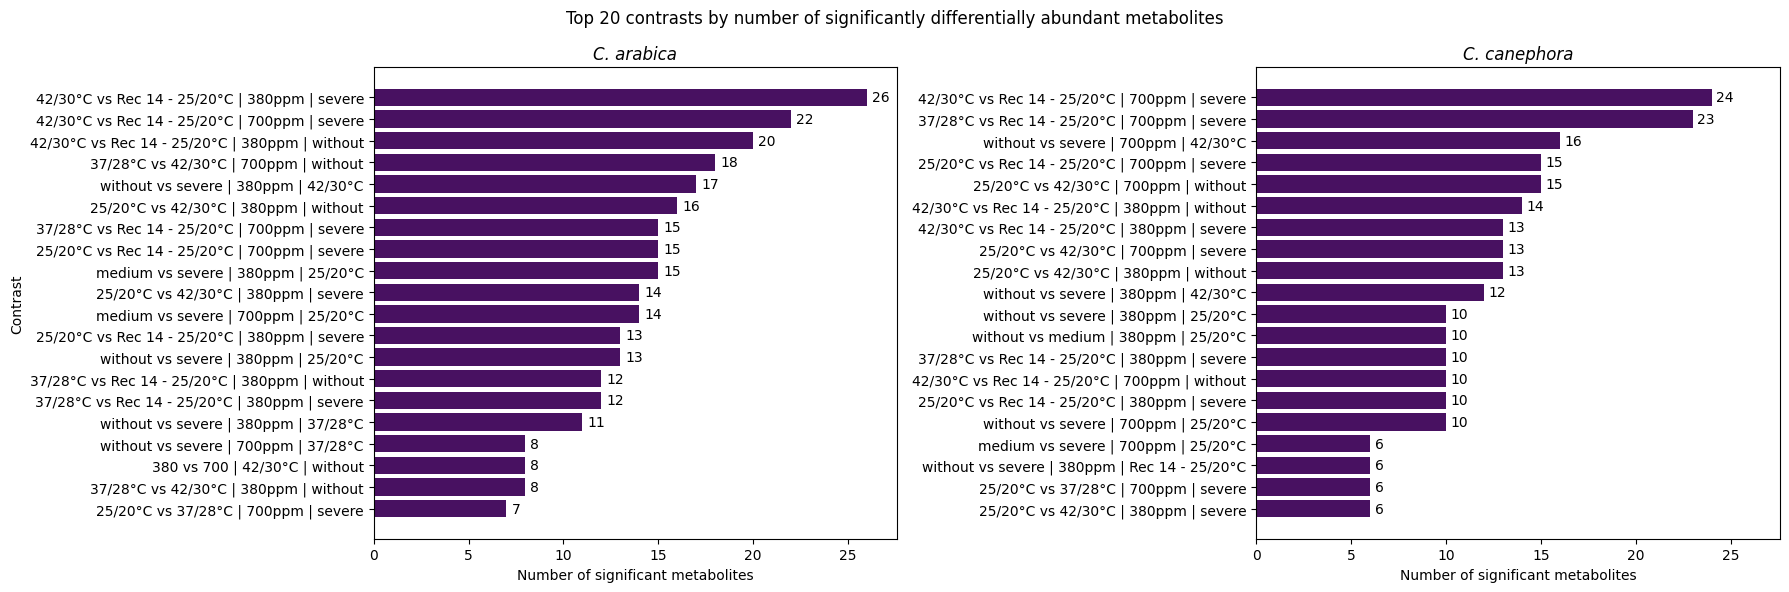

In [28]:
import matplotlib.pyplot as plt

species_list = top_contrasts_per_species["species"].unique().tolist()

fig, axes = plt.subplots(
    nrows=1, ncols=len(species_list),
    figsize=(18, 6), sharex=True
)

if len(species_list) == 1:
    axes = [axes]

for ax, species in zip(axes, species_list):
    sp_df = (
        top_contrasts_per_species[top_contrasts_per_species["species"] == species]
        .sort_values("n_highlights", ascending=True)   # ascending so barh reads top-to-bottom
    )
    bars = ax.barh(sp_df["contrast"], sp_df["n_highlights"], color="#481161")

    # Label each bar with its count, just past the end of the bar
    max_val = sp_df["n_highlights"].max()
    ax.set_xlim(0, max_val * 1.15)   # headroom so labels don't get clipped
    for bar, value in zip(bars, sp_df["n_highlights"]):
        ax.text(
            bar.get_width() + max_val * 0.01,   # small offset right of the bar
            bar.get_y() + bar.get_height() / 2,
            str(value),
            va="center", ha="left", fontsize=10
        )

    ax.set_title(species, style="italic")
    ax.set_xlabel("Number of significant metabolites")
    ax.tick_params(axis="y", labelsize=10)

axes[0].set_ylabel("Contrast")
fig.suptitle(f"Top {TOP_N} contrasts by number of significantly differentially abundant metabolites")
fig.tight_layout()
plt.show()

##Integration

In [2]:
import pandas as pd

# df is your dataframe above, with "file" as the index and
# columns: species, metabolite, contrast

df = mw_results.reset_index()  # bring "file" back as a normal column, in case you need it later

unique_metabolites_per_species = {
    species: sorted(group["metabolite"].unique())
    for species, group in df.groupby("species")
}

n_unique_metabolites_per_species = {
    species: len(metabolites)
    for species, metabolites in unique_metabolites_per_species.items()
}

# Quick summary table
summary_df = pd.DataFrame({
    "species": list(n_unique_metabolites_per_species.keys()),
    "n_unique_metabolites": list(n_unique_metabolites_per_species.values()),
})
summary_df

,species,n_unique_metabolites
0,C. arabica,46
1,C. canephora,48


In [ ]:
unique_metabolites_per_species["C. arabica"]          # -> list of unique metabolite names
unique_metabolites_per_species["C. canephora"]       # -> list of unique metabolite names


In [5]:
# Build a lowercase lookup set for fast matching
metabolomics_arabica_index_lower = {word: word.lower() for word in unique_metabolites_per_species["C. arabica"]}
metabolomics_arabica_index_lower.values()

metabolomics_canephora_index_lower = {word: word.lower() for word in unique_metabolites_per_species["C. canephora"]}
metabolomics_canephora_index_lower.values()

dict_values(['2-oxoglutarate', 'alanine', 'arginine', 'asparagine', 'aspartate', 'citrate', 'cystine', 'dehydroascorbate', 'erythritol', 'fructose', 'fumarate', 'gaba', 'galactinol', 'glucose', 'glucose-6-phosphate', 'glutamate', 'glycerate', 'glycerol', 'glycerol-3-phosphate', 'glycine', 'histidine', 'isoleucine', 'lysine', 'malate', 'methionine', 'nicotinic acid', 'ornithine', 'phenylalanine', 'phosphoric acid', 'putrescine', 'pyroglutamate', 'pyruvate', 'quinate', 'raffinose', 'rhamnose', 'serine', 'spermine', 'succinate', 'sucrose', 'threonate', 'threonine', 'trehalose', 'tryptophan', 'tyramine', 'tyrosine', 'valine', 'beta-alanine', 'myo-inositol'])

In [3]:
##Biological process
import pandas as pd
from pathlib import Path

base = Path(r"C:\Users\papan\Desktop\Coffeeomics\GOA")

layers = {
    "transcriptomics": base / "transcriptomics_pydeseq",
    "proteomics": base / "proteomics",
}

species = ["canephora", "arabica"]

go_terms = {}  # (layer, species) -> list of GO Terms

for layer_name, layer_path in layers.items():
    for sp in species:
        file_path = layer_path / "outputs" / "go_report" / sp / "non_nan" / f"go_{sp}_bp.csv"
        df = pd.read_csv(file_path, encoding="cp1252", encoding_errors="replace")
        go_terms[(layer_name, sp)] = df["GO Term"].tolist()
        print(f"{layer_name} / {sp}: {len(go_terms[(layer_name, sp)])} GO terms loaded")

# Example access:
# go_terms[("transcriptomics", "canephora")]
# go_terms[("proteomics", "arabica")]

transcriptomics / canephora: 334 GO terms loaded
transcriptomics / arabica: 318 GO terms loaded
proteomics / canephora: 27 GO terms loaded
proteomics / arabica: 23 GO terms loaded


In [ ]:
go_terms[("transcriptomics", "canephora")]

In [6]:
# Map each species name (as used in go_terms keys) to its own metabolite lookup dict
metabolomics_index_by_species = {
    "arabica": metabolomics_arabica_index_lower,
    "canephora": metabolomics_canephora_index_lower,
}

matches_by_key = {}  # (layer, species) -> {metabolite: [matching GO terms]}

for (layer, sp), terms in go_terms.items():
    index_lower = metabolomics_index_by_species[sp]
    metabolite_matches = {}
    for original_name, lower_name in index_lower.items():
        # match on either the original (key) or lowercase (value) form of the metabolite name
        found = [
            term for term in terms
            if lower_name in term.lower() or original_name.lower() in term.lower()
        ]
        if found:
            metabolite_matches[original_name] = found
    matches_by_key[(layer, sp)] = metabolite_matches


def show_matches(layer, sp):
    """Print BP GO term matches for a single layer/species combination independently."""
    print(f"=== {layer} / {sp} ===")
    for metabolite, terms in matches_by_key[(layer, sp)].items():
        print(f"{metabolite}:")
        for t in terms:
            print(f"  - {t}")


# Search independently per species, e.g.:
show_matches("transcriptomics", "canephora")
# show_matches("transcriptomics", "arabica")
# show_matches("proteomics", "canephora")
# show_matches("proteomics", "arabica")


=== transcriptomics / canephora ===
Glutamate:
  - GO:0006536 glutamate metabolic process
Glycine:
  - GO:0006544 glycine metabolic process
  - GO:0006546 glycine catabolic process
Pyruvate:
  - GO:0006090 pyruvate metabolic process
Serine:
  - GO:0000079 regulation of cyclin-dependent protein serine/threonine kinase activity
  - GO:0006563 L-serine metabolic process
  - GO:0009070 serine family amino acid biosynthetic process
  - GO:0071900 regulation of protein serine/threonine kinase activity
Spermine:
  - GO:0006597 spermine biosynthetic process
  - GO:0008215 spermine metabolic process
Sucrose:
  - GO:0005985 sucrose metabolic process
Threonine:
  - GO:0000079 regulation of cyclin-dependent protein serine/threonine kinase activity
  - GO:0071900 regulation of protein serine/threonine kinase activity
Trehalose:
  - GO:0005991 trehalose metabolic process
  - GO:0005992 trehalose biosynthetic process
Tryptophan:
  - GO:0006568 L-tryptophan metabolic process


In [9]:
import os

# --- Generate per-species GO term match reports, with metabolic and
#     non-metabolic GO terms saved to SEPARATE files ---

output_dir = r"C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics"
os.makedirs(output_dir, exist_ok=True)


def split_metabolic(terms):
    """Split a list of GO term strings into those whose description mentions
    'metabolic' and the rest."""
    metabolic = [t for t in terms if "metabolic" in t.lower()]
    other = [t for t in terms if "metabolic" not in t.lower()]
    return metabolic, other


def build_report_text(sp, wanted):
    """Build report text for one species, keeping only the metabolite/GO-term
    entries selected by `wanted` (a function terms -> filtered_terms),
    across every layer found for that species in matches_by_key."""
    layers = sorted({layer for (layer, s) in matches_by_key if s == sp})

    lines = []
    for layer in layers:
        lines.append(f"=== {layer} / {sp} ===")
        metabolite_matches = matches_by_key[(layer, sp)]
        for metabolite, terms in metabolite_matches.items():
            filtered = wanted(terms)
            if not filtered:
                continue
            lines.append(f"{metabolite}:")
            for t in filtered:
                lines.append(f"  - {t}")
        lines.append("")  # blank line between layers

    return "\n".join(lines).rstrip() + "\n"


def generate_species_reports(sp):
    """Write two separate reports for one species: metabolic GO terms only,
    and non-metabolic GO terms only."""
    metabolic_text = build_report_text(sp, lambda terms: split_metabolic(terms)[0])
    other_text = build_report_text(sp, lambda terms: split_metabolic(terms)[1])

    metabolic_path = os.path.join(output_dir, f"go_matches_{sp}_metabolic.txt")
    other_path = os.path.join(output_dir, f"go_matches_{sp}_non_metabolic.txt")

    with open(metabolic_path, "w", encoding="utf-8") as f:
        f.write(metabolic_text)
    with open(other_path, "w", encoding="utf-8") as f:
        f.write(other_text)

    print(f"Saved metabolic report for {sp} -> {metabolic_path}")
    print(f"Saved non-metabolic report for {sp} -> {other_path}")


# Generate metabolic + non-metabolic reports for each species
for sp in metabolomics_index_by_species:
    generate_species_reports(sp)


Saved metabolic report for arabica -> C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics\go_matches_arabica_metabolic.txt
Saved non-metabolic report for arabica -> C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics\go_matches_arabica_non_metabolic.txt
Saved metabolic report for canephora -> C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics\go_matches_canephora_metabolic.txt
Saved non-metabolic report for canephora -> C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics\go_matches_canephora_non_metabolic.txt


In [11]:
# --- Read the metabolic GO term reports back into memory ---
# Reuses `output_dir` from the previous cell (no path redefinition needed).

def parse_report(path):
    """Parse a go_matches_*.txt report back into {layer: {metabolite: [GO terms]}}."""
    parsed = {}
    current_layer = None
    current_metabolite = None

    with open(path, "r", encoding="utf-8") as f:
        for raw_line in f:
            line = raw_line.rstrip("\n")
            if not line:
                continue
            if line.startswith("=== ") and line.endswith(" ==="):
                header = line[4:-4]
                current_layer = header.split(" / ")[0]
                parsed[current_layer] = {}
                current_metabolite = None
            elif line.startswith("  - "):
                parsed[current_layer][current_metabolite].append(line[4:])
            elif line.endswith(":"):
                current_metabolite = line[:-1]
                parsed[current_layer][current_metabolite] = []

    return parsed


metabolic_report_paths = {
    sp: os.path.join(output_dir, f"go_matches_{sp}_metabolic.txt")
    for sp in metabolomics_index_by_species
}

metabolic_reports = {sp: parse_report(path) for sp, path in metabolic_report_paths.items()}

# Example access:
# metabolic_reports["canephora"]["transcriptomics"]["Glutamate"]

In [40]:

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from upsetplot import UpSet

UPSET_OUTPUT_DIR = Path(output_dir) / "upsetplots"
UPSET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPECIES = {
    "C. arabica": "arabica",
    "C. canephora": "canephora",
}

LAYER_ORDER = ["metabolomics", "proteomics", "transcriptomics"]

# Palette
COL_PROT = "#FFE32D"    # + proteomics only
COL_TRANS ="#FF7112"   # + transcriptomics only
COL_ALL = "#FDAA35"    # both, shared term


def build_matches(metabolites, sp_short):
    """metabolite -> {"proteomics": [...], "transcriptomics": [...]}, read
    straight from the already-parsed `metabolic_reports` instead of
    re-running the substring match against the raw GO term lists."""
    species_reports = metabolic_reports[sp_short]
    prot_by_metabolite = species_reports.get("proteomics", {})
    trans_by_metabolite = species_reports.get("transcriptomics", {})
    return {
        m: {
            "proteomics": prot_by_metabolite.get(m, []),
            "transcriptomics": trans_by_metabolite.get(m, []),
        }
        for m in metabolites
    }


def plot_species_upset(species_full, sp_short, metabolites, matches):
    # "Proteomics" + "transcriptomics" are BOTH set (the shared-term bucket)
    # only when the metabolite connects to the exact same metabolic GO term
    # in both layers' reports. Otherwise it's attributed to whichever single
    # layer it matched under (proteomics takes priority in the tie-break),
    # and flagged below as a printed note. Metabolites matching neither
    # layer are skipped entirely — no bar is drawn for them.
    memberships = []
    ambiguous = []  # metabolites matched independently in both layers, no shared term
    for m in metabolites:
        prot_terms = set(matches[m]["proteomics"])
        trans_terms = set(matches[m]["transcriptomics"])
        shared_terms = prot_terms & trans_terms

        present = set()
        if shared_terms:
            present.update({"proteomics", "transcriptomics"})
        elif prot_terms:
            present.add("proteomics")
        elif trans_terms:
            present.add("transcriptomics")

        if prot_terms and trans_terms and not shared_terms:
            ambiguous.append(m)

        if present:
            present.add("metabolomics")
            memberships.append(present)

    if ambiguous:
        print(
            f"  Note: {len(ambiguous)} metabolite(s) matched independently in "
            f"both layers but with no exact shared GO term (counted under "
            f"Proteomics only): {ambiguous}"
        )

    bool_tuples = [tuple(layer in present for layer in LAYER_ORDER) for present in memberships]
    index = pd.MultiIndex.from_tuples(bool_tuples, names=LAYER_ORDER)
    data = pd.Series(1, index=index, name="ones")

    # Custom per-layer totals (deliberately mixed units — see module notes)
    connecting_proteomics = {t for m in metabolites for t in matches[m]["proteomics"]}
    connecting_transcriptomics = {t for m in metabolites for t in matches[m]["transcriptomics"]}
    custom_totals = {
        "metabolomics": len(metabolites),
        "proteomics": len(connecting_proteomics),            # distinct GO terms
        "transcriptomics": len(connecting_transcriptomics),  # distinct GO terms
    }
    print(f"\n=== {species_full} ===")
    print(f"  Significant metabolites:             {custom_totals['metabolomics']}")
    print(f"  Connecting proteomics GO terms:      {custom_totals['proteomics']}")
    print(f"  Connecting transcriptomics GO terms: {custom_totals['transcriptomics']}")

    fig = plt.figure(figsize=(15, 5.5))
    upset = UpSet(
        data,
        subset_size="count",
        show_counts=False,
        sort_by="cardinality",
        sort_categories_by=None,      # keep our explicit LAYER_ORDER top-to-bottom
        totals_plot_elements=2,
    )
    upset.style_subsets(
        present=["metabolomics", "proteomics"], absent="transcriptomics",
        facecolor=COL_PROT, label="Proteomics BP GO terms",
    )
    upset.style_subsets(
        present=["metabolomics", "transcriptomics"], absent="proteomics",
        facecolor=COL_TRANS, label="Transcriptomics BP GO terms",
    )
    upset.style_subsets(
        present=["metabolomics", "proteomics", "transcriptomics"],
        facecolor=COL_ALL, label="Proteomics \u2229 Transcriptomics (shared BP GO terms)",
    )

    axes_dict = upset.plot(fig)
    ax_int = axes_dict["intersections"]
    ax_tot = axes_dict["totals"]
    ax_matrix = axes_dict["matrix"]

    # ── Intersection bars (top): number of METABOLITES in each combination ──
    y_max = ax_int.get_ylim()[1]
    for bar in ax_int.patches:
        h = float(bar.get_height())
        if h > 0:
            ax_int.text(
                float(bar.get_x()) + float(bar.get_width()) / 2,
                h + y_max * 0.02,
                str(int(h)),
                ha="center", va="bottom",
                fontsize=11, fontweight="bold", color="#333333",
            )
    ax_int.set_ylabel("BP GO terms associated w/ metabolites", fontsize=8)

    # ── Totals bars (left): mixed-unit custom values, bar length rescaled ──
    # Match each bar to its layer via the matrix axis' y-tick labels, which
    # share row positions with the totals bars (verified against upsetplot's
    # internal layout; do not assume patch order == LAYER_ORDER).
    category_labels = [t.get_text() for t in ax_matrix.get_yticklabels()]
    category_ticks = list(ax_matrix.get_yticks())
    label_by_ytick = dict(zip(category_ticks, category_labels))

    bars_sorted = sorted(ax_tot.patches, key=lambda b: b.get_y())
    ticks_sorted = sorted(category_ticks)

    xlim = ax_tot.get_xlim()
    inverted = xlim[0] > xlim[1]
    new_max = max(custom_totals.values())
    pad = new_max * 0.08

    # Number always sits just past the bar's tip (never on top of the bar),
    # in black.
    for bar, tick in zip(bars_sorted, ticks_sorted):
        set_name = label_by_ytick[tick]
        new_val = custom_totals[set_name]
        bar.set_x(0)
        bar.set_width(new_val)
        ax_tot.text(
            new_val + pad * 0.9,
            float(bar.get_y()) + float(bar.get_height()) / 2,
            str(new_val),
            ha="right", va="center",
            fontsize=10, fontweight="bold", color="#333333",
        )

    if inverted:
        ax_tot.set_xlim(new_max + pad, 0)
    else:
        ax_tot.set_xlim(0, new_max + pad)

    existing_legend = ax_int.get_legend()
    if existing_legend is not None:
        handles = list(existing_legend.legend_handles)
        labels = [t.get_text() for t in existing_legend.get_texts()]
        existing_legend.remove()
        ax_int.legend(
            handles, labels,
            bbox_to_anchor=(-2.5, -0.75),
            loc="upper left",
            borderaxespad=0,
            frameon=True,
            framealpha=0.9,
            title="Layer subset",
            title_fontsize=10,
            fontsize=9,
        )

    fig.suptitle(f"{species_full} — GO cross-layer overlap", style="italic")

    out_path = UPSET_OUTPUT_DIR / f"upset_layers_{sp_short}.png"
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print(f"  Saved: {out_path}")


for species_full, sp_short in SPECIES.items():
    metabolites = unique_metabolites_per_species[species_full]
    matches = build_matches(metabolites, sp_short)
    plot_species_upset(species_full, sp_short, metabolites, matches)



=== C. arabica ===
  Significant metabolites:             46
  Connecting proteomics GO terms:      1
  Connecting transcriptomics GO terms: 5
  Saved: C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics\upsetplots\upset_layers_arabica.png

=== C. canephora ===
  Significant metabolites:             48
  Connecting proteomics GO terms:      2
  Connecting transcriptomics GO terms: 8
  Saved: C:\Users\papan\Desktop\Coffeeomics\integration\metabolomics\upsetplots\upset_layers_canephora.png
